# 05 · Aggregations & Boolean Masking

**Module 02 — NumPy & Numerical Computing**

---

## What you will learn

1. `axis=` demystified — the one mental model that makes it obvious.
2. `keepdims` and why it exists.
3. Boolean masks: the vectorised replacement for `if` inside a loop.
4. `np.where`, `np.select`, `np.clip` — conditional logic without branching.
5. Fancy indexing, `argsort`, `argpartition`.
6. Counting and grouping: `unique`, `bincount`, `histogram`.

**Estimated time:** 90 minutes

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from dstoolkit import setup_plot_style
from dstoolkit.plotting import COLORS

setup_plot_style()
rng = np.random.default_rng(seed=42)

## 1. `axis=` — the only rule you need

Almost everyone gets this backwards at first, because "axis=0" sounds like "do
it to the rows". The correct reading is the opposite.

![Reading axis= correctly](../../../assets/images/axis_semantics.png)

> **`axis` names the dimension that DISAPPEARS.**

`arr.sum(axis=0)` collapses axis 0, so the rows vanish and you are left with one
value per column.

In [2]:
arr = np.arange(1, 13).reshape(3, 4)
print(f"arr (shape {arr.shape}):\n{arr}")

print(f"\narr.sum()        : {arr.sum()}          ← everything collapses, a scalar")
print(f"arr.sum(axis=0)  : {arr.sum(axis=0)}   shape {arr.sum(axis=0).shape}")
print(f"arr.sum(axis=1)  : {arr.sum(axis=1)}      shape {arr.sum(axis=1).shape}")

arr (shape (3, 4)):
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]

arr.sum()        : 78          ← everything collapses, a scalar
arr.sum(axis=0)  : [15 18 21 24]   shape (4,)
arr.sum(axis=1)  : [10 26 42]      shape (3,)


The shape arithmetic makes it mechanical: start from `(3, 4)`, delete the entry
at position `axis`, and that is your result shape.

In [3]:
cube = rng.random((2, 3, 4))

print(f"cube.shape             : {cube.shape}")
for axis in (0, 1, 2):
    result_shape = cube.sum(axis=axis).shape
    print(f"cube.sum(axis={axis}).shape : {str(result_shape):<10} "
          f"← position {axis} removed")

# Several axes at once.
print(f"\ncube.sum(axis=(0, 1)).shape : {cube.sum(axis=(0, 1)).shape}")

cube.shape             : (2, 3, 4)
cube.sum(axis=0).shape : (3, 4)     ← position 0 removed
cube.sum(axis=1).shape : (2, 4)     ← position 1 removed
cube.sum(axis=2).shape : (2, 3)     ← position 2 removed

cube.sum(axis=(0, 1)).shape : (4,)


### The reductions worth knowing

In [4]:
data = rng.normal(loc=50, scale=15, size=(4, 6)).round(1)
print(f"data:\n{data}\n")

print(f"{'reduction':<22} {'result'}")
print("-" * 60)
for name in ["sum", "mean", "std", "var", "min", "max", "ptp"]:
    fn = getattr(np, name)
    print(f"{name + '(axis=0)':<22} {np.round(fn(data, axis=0), 2)}")

print(f"\n{'median(axis=0)':<22} {np.round(np.median(data, axis=0), 2)}")
print(f"{'percentile 25':<22} {np.round(np.percentile(data, 25, axis=0), 2)}")

data:
[[43.6 44.7 58.  55.5 56.2 56.5]
 [82.1 43.9 42.3 37.8 59.2 66.9]
 [48.3 37.4 37.6 59.8 61.1 58.1]
 [40.  53.5 51.8 53.3 63.1 53.4]]

reduction              result
------------------------------------------------------------
sum(axis=0)            [214.  179.5 189.7 206.4 239.6 234.9]
mean(axis=0)           [53.5  44.88 47.42 51.6  59.9  58.72]
std(axis=0)            [16.77  5.73  7.97  8.3   2.54  5.01]
var(axis=0)            [281.31  32.81  63.44  68.94   6.46  25.13]
min(axis=0)            [40.  37.4 37.6 37.8 56.2 53.4]
max(axis=0)            [82.1 53.5 58.  59.8 63.1 66.9]
ptp(axis=0)            [42.1 16.1 20.4 22.   6.9 13.5]

median(axis=0)         [45.95 44.3  47.05 54.4  60.15 57.3 ]
percentile 25          [42.7  42.28 41.12 49.42 58.45 55.72]


> [!TIP]
> `ptp` is "peak to peak" — `max - min`. It is a fast way to check a column's
> spread, and a `ptp` of 0 immediately tells you a feature is constant and
> therefore useless to a model.

### `argmin` / `argmax` — *where*, not *what*

In [5]:
scores = np.array([0.82, 0.91, 0.78, 0.95, 0.88])
models = np.array(["ridge", "lasso", "tree", "forest", "boosting"])

best_index = scores.argmax()
print(f"scores       : {scores}")
print(f"argmax       : {best_index}   ← an INDEX, not a value")
print(f"best score   : {scores[best_index]}")
print(f"best model   : {models[best_index]}")

# In 2-D, argmax flattens by default — a classic surprise.
matrix = rng.random((3, 4))
print(f"\nmatrix.argmax()        : {matrix.argmax()}   ← index into the FLAT array")
print(f"unravel_index          : {np.unravel_index(matrix.argmax(), matrix.shape)}")
print(f"matrix.argmax(axis=1)  : {matrix.argmax(axis=1)}   ← per row")

scores       : [0.82 0.91 0.78 0.95 0.88]
argmax       : 3   ← an INDEX, not a value
best score   : 0.95
best model   : forest

matrix.argmax()        : 2   ← index into the FLAT array
unravel_index          : (np.int64(0), np.int64(2))
matrix.argmax(axis=1)  : [2 1 2]   ← per row


### `keepdims` — the argument that saves your broadcasts

A reduction removes a dimension, which then breaks the broadcast you wanted to
do next. `keepdims=True` leaves a length-1 dimension in place instead.

In [6]:
X = rng.random((4, 3))

row_sums = X.sum(axis=1)                     # shape (4,)
row_sums_kept = X.sum(axis=1, keepdims=True)  # shape (4, 1)

print(f"X shape                        : {X.shape}")
print(f"X.sum(axis=1).shape            : {row_sums.shape}")
print(f"X.sum(axis=1, keepdims=True)   : {row_sums_kept.shape}")

# Normalising rows so each sums to 1:
try:
    X / row_sums
except ValueError as exc:
    print(f"\nX / row_sums            → ValueError: {exc}")

normalised = X / row_sums_kept
print(f"X / row_sums_kept       → shape {normalised.shape}")
print(f"every row sums to 1     : {np.allclose(normalised.sum(axis=1), 1)}")

X shape                        : (4, 3)
X.sum(axis=1).shape            : (4,)
X.sum(axis=1, keepdims=True)   : (4, 1)

X / row_sums            → ValueError: operands could not be broadcast together with shapes (4,3) (4,) 
X / row_sums_kept       → shape (4, 3)
every row sums to 1     : True


> [!WARNING]
> Without `keepdims`, `(4,3) / (4,)` raises here — which is lucky. On a
> **square** matrix the same mistake broadcasts silently and normalises the
> wrong axis. Use `keepdims=True` whenever the reduction feeds a broadcast.

## 2. Boolean masks

A comparison on an array produces an array of booleans. That mask can then
select, count, or replace — no loop, no `if`.

In [7]:
values = np.array([12, 45, 7, 88, 23, 61, 4, 39])

mask = values > 30
print(f"values      : {values}")
print(f"values > 30 : {mask}")
print(f"selected    : {values[mask]}   ← a COPY, not a view")
print(f"count       : {mask.sum()}   ← True is 1, so sum counts")
print(f"proportion  : {mask.mean():.1%}   ← and mean gives the share")

values      : [12 45  7 88 23 61  4 39]
values > 30 : [False  True False  True False  True False  True]
selected    : [45 88 61 39]   ← a COPY, not a view
count       : 4   ← True is 1, so sum counts
proportion  : 50.0%   ← and mean gives the share


### Combining conditions — mind the parentheses

NumPy uses `&`, `|`, `~` for element-wise logic. Python's `and`, `or`, `not`
do **not** work, because they try to evaluate the whole array as one truth
value — the same ambiguity error you met in Module 01.

In [8]:
in_range = (values > 20) & (values < 60)
print(f"(values > 20) & (values < 60) : {values[in_range]}")

outside = (values < 10) | (values > 80)
print(f"(values < 10) | (values > 80) : {values[outside]}")

print(f"~mask (negation)              : {values[~mask]}")

try:
    values > 20 and values < 60
except ValueError as exc:
    print(f"\nusing `and` → ValueError: {str(exc)[:60]}…")

(values > 20) & (values < 60) : [45 23 39]
(values < 10) | (values > 80) : [ 7 88  4]
~mask (negation)              : [12  7 23  4]

using `and` → ValueError: The truth value of an array with more than one element is am…


> [!WARNING]
> **`&` binds tighter than `>` in Python.** Without parentheses,
> `values > 20 & values < 60` parses as `values > (20 & values) < 60` and
> either raises or — worse — silently computes something else. Always
> parenthesise each comparison.

### `any` and `all`

In [9]:
readings = np.array([[1.0, 2.0, np.nan], [4.0, 5.0, 6.0]])

print(f"readings:\n{readings}\n")
print(f"np.isnan(readings).any()        : {np.isnan(readings).any()}   ← any NaN at all?")
print(f"np.isnan(readings).any(axis=1)  : {np.isnan(readings).any(axis=1)}   ← per row")
print(f"np.isfinite(readings).all()     : {np.isfinite(readings).all()}")

# The idiomatic data-quality check.
bad_rows = np.isnan(readings).any(axis=1)
print(f"\nrows with any NaN : {np.where(bad_rows)[0]}")
print(f"clean rows        :\n{readings[~bad_rows]}")

readings:
[[ 1.  2. nan]
 [ 4.  5.  6.]]

np.isnan(readings).any()        : True   ← any NaN at all?
np.isnan(readings).any(axis=1)  : [ True False]   ← per row
np.isfinite(readings).all()     : False

rows with any NaN : [0]
clean rows        :
[[4. 5. 6.]]


### Assigning through a mask

In [10]:
temperatures = np.array([18.0, -999.0, 22.5, -999.0, 25.1])

# -999 is a sentinel for "sensor failed" — a real and common convention.
cleaned = temperatures.copy()
cleaned[cleaned == -999.0] = np.nan

print(f"raw     : {temperatures}")
print(f"cleaned : {cleaned}")
print(f"mean, naive   : {temperatures.mean():.2f}   ← catastrophically wrong")
print(f"mean, cleaned : {np.nanmean(cleaned):.2f}")

raw     : [  18.  -999.    22.5 -999.    25.1]
cleaned : [18.   nan 22.5  nan 25.1]
mean, naive   : -386.48   ← catastrophically wrong
mean, cleaned : 21.87


## 3. Conditional logic without branching

### `np.where` — vectorised if/else

In [11]:
values = np.array([-5, 3, -2, 8, 0, -1])

# np.where(condition, value_if_true, value_if_false)
clipped = np.where(values < 0, 0, values)
print(f"values                       : {values}")
print(f"where(values < 0, 0, values) : {clipped}   ← ReLU, in one line")

# All three arguments broadcast.
labels = np.where(values > 0, "positive", "non-positive")
print(f"as labels                    : {labels}")

# With one argument it returns the INDICES where the condition holds.
print(f"\nnp.where(values < 0)         : {np.where(values < 0)[0]}   ← indices")

values                       : [-5  3 -2  8  0 -1]
where(values < 0, 0, values) : [0 3 0 8 0 0]   ← ReLU, in one line
as labels                    : ['non-positive' 'positive' 'non-positive' 'positive' 'non-positive'
 'non-positive']

np.where(values < 0)         : [0 2 5]   ← indices


### `np.select` — more than two branches

In [12]:
scores = np.array([95, 72, 58, 88, 41, 67])

conditions = [scores >= 90, scores >= 70, scores >= 60]
choices = ["A", "B", "C"]

grades = np.select(conditions, choices, default="F")

print(f"scores : {scores}")
print(f"grades : {grades}")
print("\n↑ conditions are evaluated IN ORDER; the first match wins.")

scores : [95 72 58 88 41 67]
grades : ['A' 'B' 'F' 'B' 'F' 'C']

↑ conditions are evaluated IN ORDER; the first match wins.


### `np.clip` — bound values into a range

In [13]:
raw = np.array([-15.0, 5.0, 150.0, 45.0, -3.0])

print(f"raw            : {raw}")
print(f"clip(0, 100)   : {np.clip(raw, 0, 100)}")
print(f"clip(0, None)  : {np.clip(raw, 0, None)}   ← lower bound only")

# Winsorising: clip at percentiles rather than fixed values — the technique
# behind the OutlierClipper you wrote in Module 01, notebook 05.
data = rng.normal(50, 10, 1000)
data[0], data[1] = 500, -300           # inject outliers

low, high = np.percentile(data, [1, 99])
winsorised = np.clip(data, low, high)

print(f"\nbefore : min {data.min():8.2f}  max {data.max():8.2f}  "
      f"std {data.std():6.2f}")
print(f"after  : min {winsorised.min():8.2f}  max {winsorised.max():8.2f}  "
      f"std {winsorised.std():6.2f}")

raw            : [-15.   5. 150.  45.  -3.]
clip(0, 100)   : [  0.   5. 100.  45.   0.]
clip(0, None)  : [  0.   5. 150.  45.   0.]   ← lower bound only

before : min  -300.00  max   500.00  std  20.58
after  : min    26.06  max    73.28  std   9.82


## 4. Fancy indexing

Indexing with an array of **integers** selects arbitrary elements in any order,
with repetition. Unlike slicing, it always returns a **copy**.

In [14]:
arr = np.array([10, 20, 30, 40, 50])

print(f"arr[[0, 2, 4]]     : {arr[[0, 2, 4]]}")
print(f"arr[[4, 4, 0]]     : {arr[[4, 4, 0]]}   ← repeats allowed, order free")
print(f"shares memory      : {np.shares_memory(arr, arr[[0, 2]])}   ← a copy")

arr[[0, 2, 4]]     : [10 30 50]
arr[[4, 4, 0]]     : [50 50 10]   ← repeats allowed, order free
shares memory      : False   ← a copy


In [15]:
# In 2-D, index arrays pair up element-wise.
matrix = np.arange(1, 13).reshape(3, 4)
print(f"matrix:\n{matrix}\n")

rows = np.array([0, 1, 2])
cols = np.array([3, 2, 1])
print(f"matrix[rows, cols] : {matrix[rows, cols]}   ← (0,3), (1,2), (2,1)")

# Selecting whole rows in a chosen order — how you shuffle a dataset.
order = np.array([2, 0, 1])
print(f"\nmatrix[order]:\n{matrix[order]}")

matrix:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]

matrix[rows, cols] : [ 4  7 10]   ← (0,3), (1,2), (2,1)

matrix[order]:
[[ 9 10 11 12]
 [ 1  2  3  4]
 [ 5  6  7  8]]


In [16]:
# Shuffling features and labels together, keeping them aligned.
X = np.arange(10).reshape(5, 2)
y = np.array([0, 1, 0, 1, 1])

perm = rng.permutation(len(y))
X_shuffled, y_shuffled = X[perm], y[perm]

print(f"permutation : {perm}")
print(f"X_shuffled:\n{X_shuffled}")
print(f"y_shuffled  : {y_shuffled}")
print(f"\nstill aligned : "
      f"{all(np.array_equal(X_shuffled[i], X[perm[i]]) for i in range(len(perm)))}")

permutation : [1 4 3 0 2]
X_shuffled:
[[2 3]
 [8 9]
 [6 7]
 [0 1]
 [4 5]]
y_shuffled  : [1 1 1 0 0]

still aligned : True


### `argsort` — sort one array by another

In [17]:
names = np.array(["ana", "bruno", "carla", "diego"])
revenue = np.array([340.0, 120.5, 890.0, 55.2])

order = revenue.argsort()[::-1]        # descending

print(f"argsort (ascending)  : {revenue.argsort()}")
print(f"reversed (descending): {order}")
print(f"\nranked:")
for rank, i in enumerate(order, start=1):
    print(f"  {rank}. {names[i]:<7} {revenue[i]:>7.2f}")

argsort (ascending)  : [3 1 0 2]
reversed (descending): [2 0 1 3]

ranked:
  1. carla    890.00
  2. ana      340.00
  3. bruno    120.50
  4. diego     55.20


### `argpartition` — the top *k* without a full sort

When you only need the largest few, sorting everything is wasted work.
`argpartition` is **O(n)** where `argsort` is **O(n log n)**.

In [18]:
import time

large = rng.random(2_000_000)
k = 10

start = time.perf_counter()
top_sorted = large.argsort()[-k:]
t_sort = time.perf_counter() - start

start = time.perf_counter()
# Guarantees the last k positions hold the k largest, unordered among themselves.
top_partition = np.argpartition(large, -k)[-k:]
t_part = time.perf_counter() - start

print(f"argsort      : {t_sort * 1000:7.2f} ms")
print(f"argpartition : {t_part * 1000:7.2f} ms   ({t_sort / t_part:.0f}× faster)")
print(f"\nsame top-{k} values : "
      f"{np.array_equal(np.sort(large[top_sorted]), np.sort(large[top_partition]))}")

argsort      :  230.97 ms
argpartition :   22.75 ms   (10× faster)

same top-10 values : True


## 5. Counting and grouping

In [19]:
channels = rng.choice([0, 1, 2, 3], size=1000, p=[0.4, 0.3, 0.2, 0.1])

# unique with counts — the NumPy equivalent of collections.Counter.
values, counts = np.unique(channels, return_counts=True)
print(f"values : {values}")
print(f"counts : {counts}")

# bincount is faster for small non-negative integers.
print(f"\nbincount : {np.bincount(channels)}")

values : [0 1 2 3]
counts : [400 292 216  92]

bincount : [400 292 216  92]


In [20]:
# unique also returns the inverse mapping — this is label encoding.
labels = np.array(["paid", "organic", "paid", "email", "organic"])
categories, encoded = np.unique(labels, return_inverse=True)

print(f"labels     : {labels}")
print(f"categories : {categories}")
print(f"encoded    : {encoded}   ← integer codes")
print(f"decoded    : {categories[encoded]}   ← round trips exactly")

labels     : ['paid' 'organic' 'paid' 'email' 'organic']
categories : ['email' 'organic' 'paid']
encoded    : [2 1 2 0 1]   ← integer codes
decoded    : ['paid' 'organic' 'paid' 'email' 'organic']   ← round trips exactly


### Group-wise aggregation without pandas

This is `groupby().sum()` implemented from first principles. Understanding it
makes Module 03 much less mysterious.

In [21]:
group_ids = np.array([0, 1, 0, 2, 1, 0, 2])
amounts = np.array([10.0, 20.0, 5.0, 8.0, 12.0, 3.0, 15.0])

# bincount with `weights` sums the weights per bin — a group-by in one call.
group_sums = np.bincount(group_ids, weights=amounts)
group_counts = np.bincount(group_ids)
group_means = group_sums / group_counts

print(f"group ids : {group_ids}")
print(f"amounts   : {amounts}")
print(f"\n{'group':>6} {'count':>6} {'sum':>8} {'mean':>8}")
print("-" * 32)
for g in range(len(group_sums)):
    print(f"{g:>6} {group_counts[g]:>6} {group_sums[g]:>8.1f} {group_means[g]:>8.2f}")

group ids : [0 1 0 2 1 0 2]
amounts   : [10. 20.  5.  8. 12.  3. 15.]

 group  count      sum     mean
--------------------------------
     0      3     18.0     6.00
     1      2     32.0    16.00
     2      2     23.0    11.50


In [22]:
# Cross-check against pandas.
import pandas as pd

reference = (
    pd.DataFrame({"g": group_ids, "amount": amounts})
    .groupby("g")["amount"]
    .agg(["count", "sum", "mean"])
)
print(reference)
print(f"\nmeans agree with pandas : "
      f"{np.allclose(group_means, reference['mean'].to_numpy())}")

   count   sum  mean
g                   
0      3  18.0   6.0
1      2  32.0  16.0
2      2  23.0  11.5

means agree with pandas : True


### Binning with `digitize` and `histogram`

In [23]:
ages = rng.integers(18, 80, 500)
bin_edges = np.array([18, 30, 45, 60, 100])

# digitize returns which bin each value falls into (1-indexed by default).
bin_index = np.digitize(ages, bin_edges)
bin_labels = np.array(["", "18-29", "30-44", "45-59", "60+"])

counts, _ = np.histogram(ages, bins=bin_edges)

print(f"{'bin':>8} {'count':>7}")
print("-" * 17)
for label, count in zip(bin_labels[1:], counts, strict=True):
    bar = "█" * int(count / counts.max() * 22)
    print(f"{label:>8} {count:>7}  {bar}")

     bin   count
-----------------
   18-29      94  ████████████
   30-44     129  █████████████████
   45-59     111  ██████████████
     60+     166  ██████████████████████


## 6. Putting it together — a vectorised quality report

In [24]:
def quality_report(X: np.ndarray, feature_names: list[str]) -> pd.DataFrame:
    """Profile a numeric feature matrix using only vectorised operations.

    Parameters
    ----------
    X : ndarray of shape (n_samples, n_features)
        The data to profile.
    feature_names : list of str
        One name per column.

    Returns
    -------
    DataFrame
        One row per feature.
    """
    if X.shape[1] != len(feature_names):
        raise ValueError(
            f"X has {X.shape[1]} columns but {len(feature_names)} names were given"
        )

    finite = np.isfinite(X)
    # Outliers by the 1.5×IQR rule, computed per column.
    q1, q3 = np.nanpercentile(X, [25, 75], axis=0)
    iqr = q3 - q1
    is_outlier = (X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)

    return pd.DataFrame({
        "feature": feature_names,
        "missing_%": (~finite).mean(axis=0) * 100,
        "mean": np.nanmean(X, axis=0),
        "std": np.nanstd(X, axis=0),
        "min": np.nanmin(X, axis=0),
        "median": np.nanmedian(X, axis=0),
        "max": np.nanmax(X, axis=0),
        "outliers_%": np.nansum(is_outlier, axis=0) / len(X) * 100,
        "constant": np.nanstd(X, axis=0) == 0,
    }).set_index("feature").round(2)


# A realistic messy matrix.
n = 2000
X = np.column_stack([
    rng.normal(50, 10, n),                       # well behaved
    rng.lognormal(3, 1, n),                      # skewed, will show outliers
    np.full(n, 7.0),                             # constant — useless feature
    rng.normal(0, 1, n),
])
X[rng.choice(n, 60, replace=False), 0] = np.nan  # inject missingness

quality_report(X, ["normal", "skewed", "constant", "standard"])

,missing_%,mean,std,min,median,max,outliers_%,constant
feature,,,,,,,,
normal,3.0,49.71,10.19,9.01,49.88,88.25,0.80,False
skewed,0.0,33.78,47.33,0.87,21.17,1134.48,6.65,False
constant,0.0,7.00,0.00,7.00,7.00,7.00,0.00,True
standard,0.0,0.03,0.98,-2.95,0.05,3.39,0.55,False


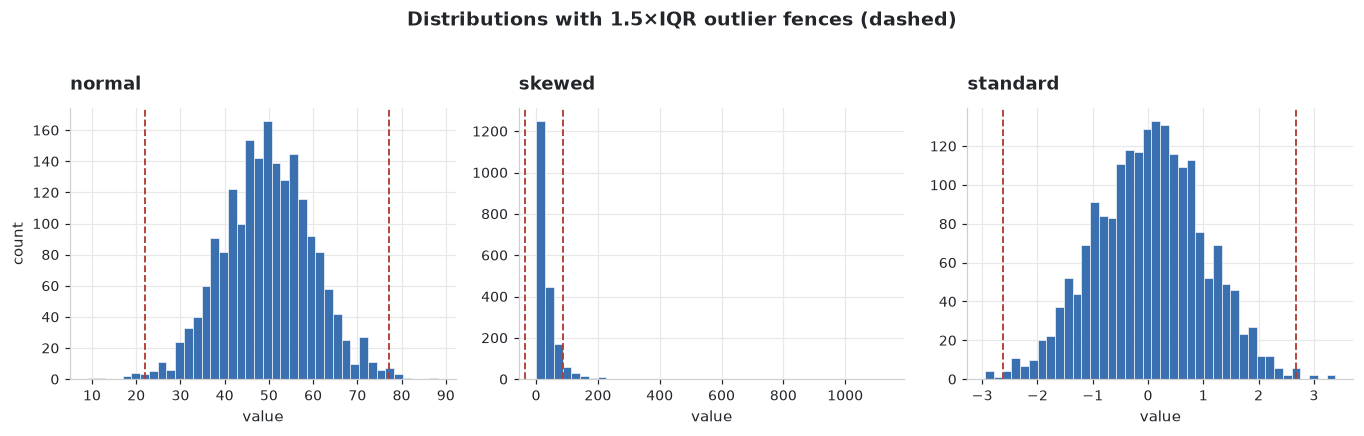

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))

for ax, (col, name) in zip(
    axes, [(0, "normal"), (1, "skewed"), (3, "standard")], strict=True
):
    column = X[:, col]
    column = column[np.isfinite(column)]

    ax.hist(column, bins=40, color=COLORS["primary"],
            edgecolor="white", linewidth=0.4)

    # Mark the IQR outlier fences so the report's numbers are visible.
    q1, q3 = np.percentile(column, [25, 75])
    iqr = q3 - q1
    for fence in (q1 - 1.5 * iqr, q3 + 1.5 * iqr):
        ax.axvline(fence, color=COLORS["danger"], linestyle="--", linewidth=1.2)

    ax.set_title(name)
    ax.set_xlabel("value")
    ax.set_ylabel("count" if col == 0 else "")

fig.suptitle("Distributions with 1.5×IQR outlier fences (dashed)",
             fontsize=12.5, y=1.03)
fig.tight_layout()
plt.show()

## 7. Exercises

### Exercise 5.1 — Axis drill

For `a = np.arange(24).reshape(2, 3, 4)`, give the shape of each result before
running it:

```python
a.sum(axis=0)      a.sum(axis=1)      a.sum(axis=2)
a.sum(axis=(0, 2)) a.mean(axis=1, keepdims=True)   a.max(axis=-1)
```

### Exercise 5.2 — The keepdims trap

Given `X` of shape `(5, 5)`, write `X / X.sum(axis=1)` and
`X / X.sum(axis=1, keepdims=True)`. Both run. Show that the first is wrong, and
explain precisely what it computed.

### Exercise 5.3 — Masking practice

For `data = rng.normal(100, 20, 10_000)`:

1. How many values lie outside two standard deviations of the mean?
2. Replace them with the mean, without a loop.
3. Report the share of values in `[80, 120]`.

### Exercise 5.4 — Group-by from scratch

Write `group_stats(keys, values)` returning, per unique key, the count, sum,
mean, and max — using only NumPy. Handle string keys via
`np.unique(..., return_inverse=True)`. Check against pandas.

### Exercise 5.5 — Top-k per row

Given `scores` of shape `(1000, 50)` (1000 users × 50 items), find each user's
top 5 items using `argpartition`, and return a `(1000, 5)` array of item
indices sorted by score descending. This is the core of a recommender's serving
path.

## Key takeaways

- **`axis` names the dimension that disappears.** Delete that entry from the
  shape tuple and you have the result shape.
- **`keepdims=True`** whenever the reduction feeds a broadcast — it prevents a
  whole class of silent errors on square arrays.
- `argmin`/`argmax` return **indices**; in 2-D they flatten unless you pass an
  axis. `np.unravel_index` converts back.
- Boolean masks replace `if` inside a loop. Combine with **`&`, `|`, `~`** and
  **always parenthesise** each comparison.
- `mask.sum()` counts and `mask.mean()` gives the proportion — booleans are
  just 0 and 1.
- **`np.where`** is vectorised if/else; **`np.select`** handles many branches;
  **`np.clip`** bounds a range.
- **Fancy indexing returns a copy** and permits repeats and arbitrary order.
- Use **`argpartition`** rather than `argsort` when you only need the top *k*.
- **`np.bincount(ids, weights=values)`** is a group-by sum in one call.

---

**Next:** [06 · Linear Algebra](06_linear_algebra.ipynb) — the mathematics every
model in this course runs on.